<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Pr%C3%A1tica7Quest%C3%A3o3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Estrutura: H(z) = H_PB1(z) H_PB2(z) - H_PA1(z) H_PA2(z)
PB1: polos em f = 313.7 Hz, r = 0.8633   H(z) = (0.00677 z^2 +0.01353 z +0.00677) / (z^2 -1.71821 z +0.74528)
PB2: polos em f = 921.0 Hz, r = 0.9541   H(z) = (0.02036 z^2 +0.04071 z +0.02036) / (z^2 -1.82890 z +0.91032)
PA1: polos em f = 6793.5 Hz, r = 0.5329   H(z) = (0.17869 z^2 -0.35737 z +0.17869) / (z^2 +0.56924 z +0.28399)
PA2: polos em f = 4227.7 Hz, r = 0.8928   H(z) = (0.55652 z^2 -1.11303 z +0.55652) / (z^2 -0.42900 z +0.79707)
b = [-0.099305  0.751074 -2.483699  4.714945 -5.603834  4.278502 -2.04578
  0.56112  -0.067435]
a = [ 1.       -3.406861  5.137424 -4.8908    3.3323   -1.564964  0.682342
 -0.437428  0.153575]
polos = [ 0.2145+0.8666j  0.2145-0.8666j -0.2846+0.4505j -0.2846-0.4505j
  0.9144+0.2722j  0.9144-0.2722j  0.8591+0.0849j  0.8591-0.0849j]
|p| = [0.8928 0.8928 0.5329 0.5329 0.9541 0.9541 0.8633 0.8633]
zeros = [2.0916+0.j     1.2581+0.8063j 1.2581-0.8063j 0.7249+0.5863j
 0.7249-0.5863j 0.5222+0.2999j 0.5222

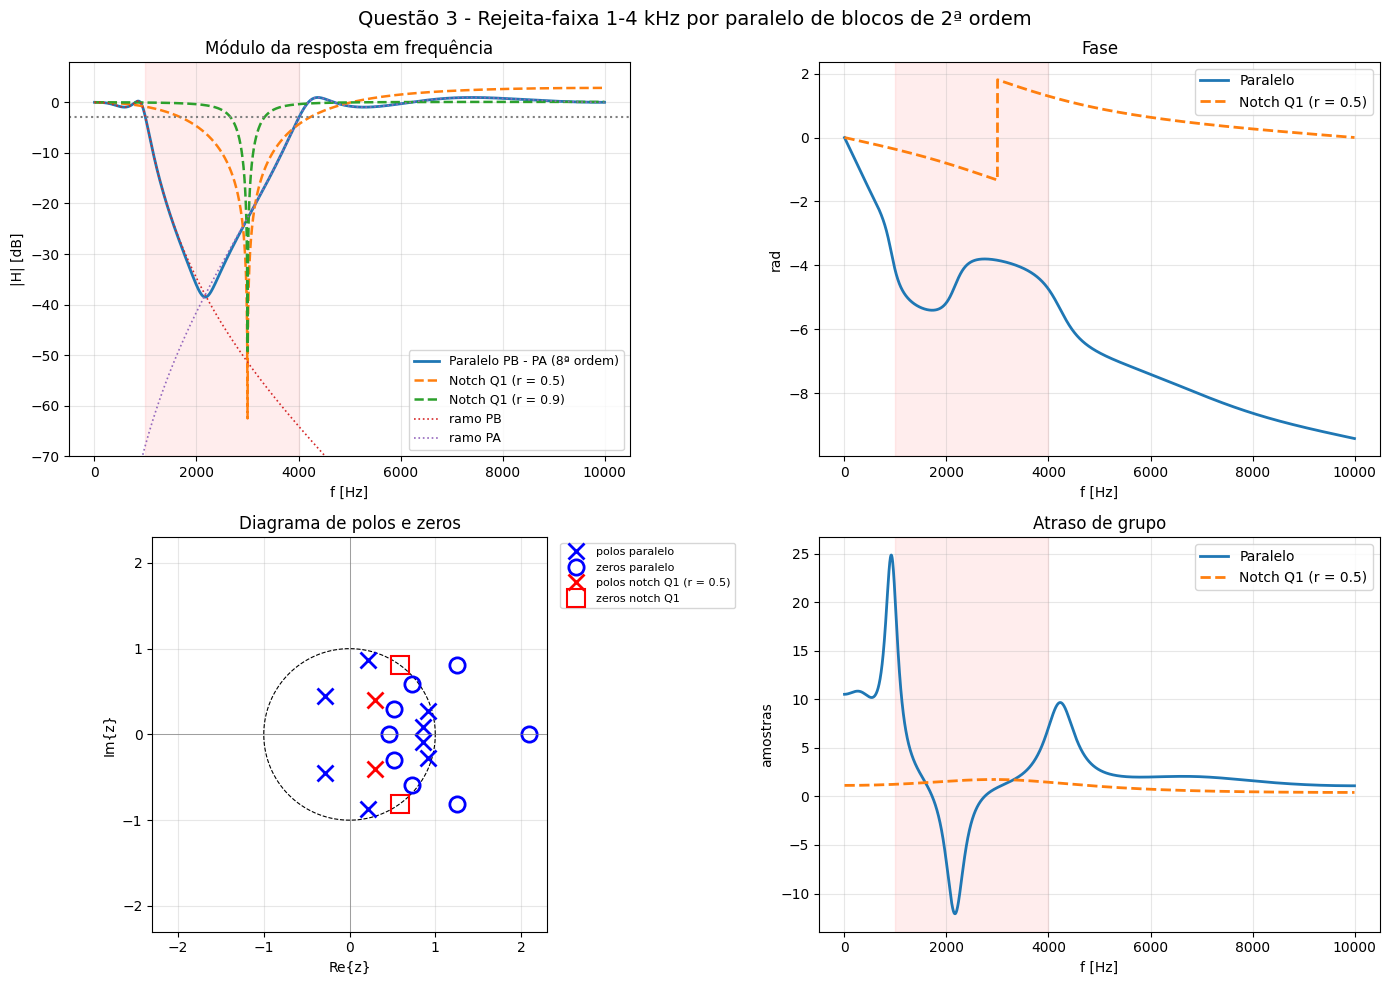

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, optimize

fs = 20000
fc1, fc2 = 1000, 4000
f_notch = 3000
f = np.linspace(1, fs / 2 - 1, 4000)
zf = np.exp(2j * np.pi * f / fs)


def bloco(tipo, fp, r):
    th = 2 * np.pi * fp / fs
    a = np.array([1.0, -2 * r * np.cos(th), r ** 2])
    if tipo == "pb":
        b = np.array([1.0, 2.0, 1.0])
        g = np.polyval(a, 1.0) / np.polyval(b, 1.0)
    elif tipo == "pa":
        b = np.array([1.0, -2.0, 1.0])
        g = np.polyval(a, -1.0) / np.polyval(b, -1.0)
    elif tipo == "notch":
        b = np.array([1.0, -2 * np.cos(th), 1.0])
        g = np.polyval(a, 1.0) / np.polyval(b, 1.0)
    return g * b, a


def ramos(x):
    ramo_pb = [bloco("pb", x[0], x[1]), bloco("pb", x[2], x[3])]
    ramo_pa = [bloco("pa", x[4], x[5]), bloco("pa", x[6], x[7])]
    return ramo_pb, ramo_pa


def resp_ramo(ramo):
    H = np.ones_like(zf)
    for b, a in ramo:
        H = H * np.polyval(b, zf) / np.polyval(a, zf)
    return H


def resposta(x):
    ramo_pb, ramo_pa = ramos(x)
    return resp_ramo(ramo_pb) - resp_ramo(ramo_pa)


def db(H):
    return 20 * np.log10(np.abs(H) + 1e-12)


def valor(d, fe):
    return np.interp(fe, f, d)


def custo(x):
    for i in (1, 3, 5, 7):
        if not 0 < x[i] < 0.995:
            return 1e6
    for i in (0, 2, 4, 6):
        if not 20 < x[i] < 9980:
            return 1e6
    d = db(resposta(x))
    passa = (f <= fc1) | (f >= fc2)
    passa_int = (f <= fc1 - 100) | (f >= fc2 + 300)
    rejeita = (f >= 1400) & (f <= 3200)
    return (10 * ((valor(d, fc1) + 3) ** 2 + (valor(d, fc2) + 3) ** 2) + np.mean(d[passa] ** 2)
            + 0.02 * np.mean(np.clip(d[rejeita] + 50, 0, None) ** 2) + 5 * np.max(np.abs(d[passa_int])) ** 2
            + 2 * max(0.0, d[rejeita].max() + 20) ** 2)


x0 = [500, 0.9, 900, 0.9, 5000, 0.7, 4200, 0.9]
res = optimize.minimize(custo, x0, method="Nelder-Mead", options={"maxiter": 40000, "maxfev": 40000, "xatol": 1e-7, "fatol": 1e-11})
res = optimize.minimize(custo, res.x, method="Nelder-Mead", options={"maxiter": 40000, "maxfev": 40000, "xatol": 1e-7, "fatol": 1e-11})
xo = res.x
ramo_pb, ramo_pa = ramos(xo)

print("Estrutura: H(z) = H_PB1(z) H_PB2(z) - H_PA1(z) H_PA2(z)")
nomes = ["PB1", "PB2", "PA1", "PA2"]
for i, (nome, (b, a)) in enumerate(zip(nomes, ramo_pb + ramo_pa)):
    print(f"{nome}: polos em f = {xo[2 * i]:.1f} Hz, r = {xo[2 * i + 1]:.4f}   "
          f"H(z) = ({b[0]:.5f} z^2 {b[1]:+.5f} z {b[2]:+.5f}) / (z^2 {a[1]:+.5f} z {a[2]:+.5f})")

b_pb = np.convolve(ramo_pb[0][0], ramo_pb[1][0])
a_pb = np.convolve(ramo_pb[0][1], ramo_pb[1][1])
b_pa = np.convolve(ramo_pa[0][0], ramo_pa[1][0])
a_pa = np.convolve(ramo_pa[0][1], ramo_pa[1][1])
b_tot = np.polysub(np.convolve(b_pb, a_pa), np.convolve(b_pa, a_pb))
a_tot = np.convolve(a_pb, a_pa)
print("b =", np.round(b_tot, 6))
print("a =", np.round(a_tot, 6))
z_tot, p_tot, _ = signal.tf2zpk(b_tot, a_tot)
print("polos =", np.round(p_tot, 4))
print("|p| =", np.round(np.abs(p_tot), 4))
print("zeros =", np.round(z_tot, 4))
print("|zeros| =", np.round(np.abs(z_tot), 4))
print("ângulo dos zeros [Hz] =", np.round(np.abs(np.angle(z_tot)) * fs / (2 * np.pi), 1))
print("Estável:", np.all(np.abs(p_tot) < 1))


def bordas(d, nivel=-3):
    c = np.where(np.diff((d >= nivel).astype(int)) != 0)[0]
    return [f[i] + (nivel - d[i]) * (f[i + 1] - f[i]) / (d[i + 1] - d[i]) for i in c]


r_notch = [0.5, 0.9]
notches = [bloco("notch", f_notch, r) for r in r_notch]
print(f"\nNotch da questão 1 (f0 = {f_notch} Hz) com r = 0.5 (o mais largo testado) e r = 0.9")

H_p = resposta(xo)
d_p = db(H_p)
d_ns = [db(np.polyval(bn, zf) / np.polyval(an, zf)) for bn, an in notches]
passa = (f <= fc1) | (f >= fc2)
passa_int = (f <= 800) | (f >= 4500)
faixa = (f >= 1500) & (f <= 3000)


def largura(d, nivel):
    e = bordas(d, nivel)
    return e[-1] - e[0] if len(e) >= 2 else np.nan


cols = [d_p] + d_ns
print("\nComparação")
print(f"{'':32}{'Paralelo (8a ordem)':>21}{'Notch r=0.5':>14}{'Notch r=0.9':>14}")
print(f"{'Bordas -3 dB [Hz]':32}" + f"{str(np.round(bordas(d_p), 0)):>21}" + "".join(f"{str(np.round(bordas(d), 0)):>14}" for d in d_ns))
linhas = [
    ("Ganho máx fora 1-4 kHz [dB]", lambda d: d[passa].max()),
    ("Ondulação <0,8 e >4,5 kHz [dB]", lambda d: np.ptp(d[passa_int])),
    ("Ganho em 1500 Hz [dB]", lambda d: valor(d, 1500)),
    ("Ganho em 2000 Hz [dB]", lambda d: valor(d, 2000)),
    ("Ganho em 2500 Hz [dB]", lambda d: valor(d, 2500)),
    ("Ganho em 3000 Hz [dB]", lambda d: valor(d, 3000)),
    ("Ganho em 3500 Hz [dB]", lambda d: valor(d, 3500)),
    ("Pior atenuação 1,5-3 kHz [dB]", lambda d: d[faixa].max()),
    ("Largura a -3 dB [Hz]", lambda d: largura(d, -3)),
    ("Largura a -10 dB [Hz]", lambda d: largura(d, -10)),
    ("Largura a -20 dB [Hz]", lambda d: largura(d, -20)),
]
for nome, fn in linhas:
    print(f"{nome:32}{fn(d_p):>21.2f}" + "".join(f"{fn(d):>14.2f}" for d in d_ns))
print(f"Mínimo de |H| do paralelo: {d_p.min():.1f} dB em {f[np.argmin(d_p)]:.0f} Hz (notch: zero exato em 3000 Hz)")

b_n, a_n = notches[0]
r1 = r_notch[0]
H_n = np.polyval(b_n, zf) / np.polyval(a_n, zf)
d_n = d_ns[0]

gd_p = -np.gradient(np.unwrap(np.angle(H_p)), 2 * np.pi * f / fs)
gd_n = -np.gradient(np.unwrap(np.angle(H_n)), 2 * np.pi * f / fs)
gd_n[np.abs(f - f_notch) < 30] = np.nan

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0, 0].plot(f, d_p, lw=2, label="Paralelo PB - PA (8ª ordem)")
for (r_, d_) in zip(r_notch, d_ns):
    ax[0, 0].plot(f, d_, "--", lw=1.8, label=f"Notch Q1 (r = {r_})")
ax[0, 0].plot(f, db(resp_ramo(ramo_pb)), ":", lw=1.2, label="ramo PB")
ax[0, 0].plot(f, db(resp_ramo(ramo_pa)), ":", lw=1.2, label="ramo PA")
ax[0, 0].axvspan(fc1, fc2, color="red", alpha=0.07)
ax[0, 0].axhline(-3, color="gray", ls=":")
ax[0, 0].set_ylim(-70, 8)
ax[0, 0].set_title("Módulo da resposta em frequência")
ax[0, 0].set_xlabel("f [Hz]")
ax[0, 0].set_ylabel("|H| [dB]")
ax[0, 0].legend(fontsize=9)

ax[0, 1].plot(f, np.unwrap(np.angle(H_p)), lw=2, label="Paralelo")
ax[0, 1].plot(f, np.unwrap(np.angle(H_n)), "--", lw=2, label="Notch Q1 (r = 0.5)")
ax[0, 1].axvspan(fc1, fc2, color="red", alpha=0.07)
ax[0, 1].set_title("Fase")
ax[0, 1].set_xlabel("f [Hz]")
ax[0, 1].set_ylabel("rad")
ax[0, 1].legend()

t = np.linspace(0, 2 * np.pi, 400)
zn, pn, _ = signal.tf2zpk(b_n, a_n)
ax[1, 0].plot(np.cos(t), np.sin(t), "k--", lw=0.8)
ax[1, 0].plot(p_tot.real, p_tot.imag, "bx", ms=11, mew=2, label="polos paralelo")
ax[1, 0].plot(z_tot.real, z_tot.imag, "bo", mfc="none", ms=11, mew=2, label="zeros paralelo")
ax[1, 0].plot(pn.real, pn.imag, "rx", ms=11, mew=2, label="polos notch Q1 (r = 0.5)")
ax[1, 0].plot(zn.real, zn.imag, "rs", mfc="none", ms=13, mew=1.5, label="zeros notch Q1")
ax[1, 0].set_aspect("equal")
lim = max(1.3, np.max(np.abs(z_tot)) * 1.1)
ax[1, 0].set_xlim(-lim, lim)
ax[1, 0].set_ylim(-lim, lim)
ax[1, 0].axhline(0, color="gray", lw=0.5)
ax[1, 0].axvline(0, color="gray", lw=0.5)
ax[1, 0].set_title("Diagrama de polos e zeros")
ax[1, 0].set_xlabel("Re{z}")
ax[1, 0].set_ylabel("Im{z}")
ax[1, 0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))

ax[1, 1].plot(f, gd_p, lw=2, label="Paralelo")
ax[1, 1].plot(f, gd_n, "--", lw=2, label="Notch Q1 (r = 0.5)")
ax[1, 1].axvspan(fc1, fc2, color="red", alpha=0.07)
ax[1, 1].set_title("Atraso de grupo")
ax[1, 1].set_xlabel("f [Hz]")
ax[1, 1].set_ylabel("amostras")
ax[1, 1].legend()
for a_ in ax.flat:
    a_.grid(alpha=0.3)
fig.suptitle("Questão 3 - Rejeita-faixa 1-4 kHz por paralelo de blocos de 2ª ordem", fontsize=14)
fig.tight_layout()
plt.savefig("questao3.png", dpi=110)
plt.show()

O rejeita-faixas foi feito com dois ramos em paralelo, H(z) = H_PB1 H_PB2 - H_PA1 H_PA2. O ramo passa-baixas deixa passar abaixo de 1 kHz e o ramo passa-altas acima de 4 kHz. Na faixa de rejeição os dois ramos têm módulos parecidos, e a subtração faz com que eles se cancelem, o que aprofunda o vale até -38,6 dB em 2151 Hz. Os parâmetros dos blocos foram ajustados numericamente.

O resultado tem bordas de -3 dB em 999 e 4011 Hz, ondulação de 1,55 dB nas bandas passantes e pelo menos 22,5 dB de atenuação entre 1,5 e 3 kHz. O filtro é de 8ª ordem. Os polos são os dos quatro blocos, todos com módulo menor que 0,95, então o filtro é estável. Já os zeros surgem da soma dos ramos: nenhum fica sobre o círculo unitário e alguns ficam fora dele, de modo que não há um nulo exato e o filtro é de fase não mínima.

O notch da questão 1 tem atenuação infinita em 3000 Hz, mas só nessa frequência. Mesmo com r = 0,5 ele atenua apenas 2,2 dB em 1,5 kHz e 4,7 dB em 2 kHz. Com r = 0,9 a faixa rejeitada tem só 658 Hz. Ou seja, o notch serve para eliminar uma frequência isolada, enquanto o filtro em paralelo rejeita uma banda larga com bordas íngremes, ao custo de uma ordem maior e de atenuação finita.